# Лабораторная работа 02
## Часть 1. Базовый конвейер анализа данных в Pandas

**ФИО:** Годуленко Матвей
**Группа:** ЕТ-213

**Цель работы:** освоить базовый конвейер обработки табличных данных средствами Python, NumPy и Pandas:
формирование данных → сохранение → загрузка → проверка структуры и качества → выборка → фильтрация → расчёт статистик → группировка → формирование аналитического вывода.

## 3. Формирование и сохранение исходных данных

### Задание 3.1
Импортируем библиотеки, создаём словарь `raw_data`, переводим его в `DataFrame` и сохраняем в `online_store_orders.csv`.

In [1]:
import numpy as np
import pandas as pd

raw_data = {
    "order_id": [
        1001, 1002, 1003, 1004, 1005,
        1006, 1007, 1008, 1009, 1010,
        1011, 1012, 1013, 1014, 1015
    ],

    "channel": [
        "site", "app", "app", "marketplace", "site",
        "app", "site", "marketplace", "app", "site",
        "marketplace", "app", "site", "site", "marketplace"
    ],

    "order_sum": [
        1200, 2500, 1800, 3200, 900,
        1500, 2800, 45000, 2100, 1700,
        3600, 1100, 2400, 1900, 3300
    ],

    "delivery_time": [
        25, np.nan, 40, 55, 20,
        30, np.nan, 70, 35, 45,
        50, 18, 27, np.nan, 60
    ],

    "rating": [
        5, 4, 5, 3, 5,
        4, 2, 1, 5, 4,
        3, 5, 4, 5, 2
    ]
}

df = pd.DataFrame(raw_data)

print(df)

df.to_csv("online_store_orders.csv", index=False)

    order_id      channel  order_sum  delivery_time  rating
0       1001         site       1200           25.0       5
1       1002          app       2500            NaN       4
2       1003          app       1800           40.0       5
3       1004  marketplace       3200           55.0       3
4       1005         site        900           20.0       5
5       1006          app       1500           30.0       4
6       1007         site       2800            NaN       2
7       1008  marketplace      45000           70.0       1
8       1009          app       2100           35.0       5
9       1010         site       1700           45.0       4
10      1011  marketplace       3600           50.0       3
11      1012          app       1100           18.0       5
12      1013         site       2400           27.0       4
13      1014         site       1900            NaN       5
14      1015  marketplace       3300           60.0       2


### Контрольный вопрос
**Для чего используется параметр `index=False`? Что произойдёт при сохранении таблицы без этого параметра?**

**Ответ:** параметр `index=False` говорит pandas не записывать индекс DataFrame (0, 1, 2, …) в CSV-файл.
Без него индекс сохранится как отдельный первый столбец без названия. При повторной загрузке через `pd.read_csv()`
этот столбец появится в таблице как лишний столбец `Unnamed: 0`, который не несёт полезной информации
и дублирует индекс — его придётся удалять вручную или указывать `index_col=0`.

## 4. Загрузка и первичный анализ данных

### Задание 4.1
Дальше работаем только с данными, загруженными из файла `online_store_orders.csv`.

In [2]:
store_df = pd.read_csv("online_store_orders.csv")

print("Первые 5 строк:")
print(store_df.head())

print("\nПоследние 5 строк:")
print(store_df.tail())

print("\nРазмер таблицы:")
print(store_df.shape)

print("\nНазвания столбцов:")
print(store_df.columns)

print("\nИнформация о таблице:")
store_df.info()

Первые 5 строк:
   order_id      channel  order_sum  delivery_time  rating
0      1001         site       1200           25.0       5
1      1002          app       2500            NaN       4
2      1003          app       1800           40.0       5
3      1004  marketplace       3200           55.0       3
4      1005         site        900           20.0       5

Последние 5 строк:
    order_id      channel  order_sum  delivery_time  rating
10      1011  marketplace       3600           50.0       3
11      1012          app       1100           18.0       5
12      1013         site       2400           27.0       4
13      1014         site       1900            NaN       5
14      1015  marketplace       3300           60.0       2

Размер таблицы:
(15, 5)

Названия столбцов:
Index(['order_id', 'channel', 'order_sum', 'delivery_time', 'rating'], dtype='str')

Информация о таблице:
<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 5 columns):
 #   Co

In [3]:
# дополнительно посмотрим типы данных отдельно
store_df.dtypes

order_id           int64
channel              str
order_sum          int64
delivery_time    float64
rating             int64
dtype: object

### Контрольные вопросы
По результатам выполнения кода:

1. **Количество строк:** 15 (каждая строка — один заказ).
2. **Количество столбцов:** 5 (`order_id`, `channel`, `order_sum`, `delivery_time`, `rating`).
3. **Числовые столбцы:** `order_id` (int64), `order_sum` (int64), `delivery_time` (float64), `rating` (int64).
   Столбец `channel` — текстовый (строковый тип).
4. **Столбцы с пропущенными значениями:** только `delivery_time` (в `info()` у него 12 non-null из 15).
5. **Количество пропущенных значений:** 3 (15 − 12 = 3).

Кстати, `delivery_time` имеет тип `float64`, а не `int64`, как раз из-за пропусков: `NaN` в pandas — это значение типа float.

## 5. Выборка и фильтрация данных

### 5.1. Выбор столбцов

In [4]:
store_df[["order_sum", "delivery_time"]]

,order_sum,delivery_time
0,1200,25.0
1,2500,NaN
2,1800,40.0
3,3200,55.0
4,900,20.0
5,1500,30.0
6,2800,NaN
7,45000,70.0
8,2100,35.0
9,1700,45.0


### 5.2. Выбор строк
Строки с индексами от 3 до 7 включительно. Так как у `.iloc` правая граница не включается, пишем `3:8`.
Столбцы `order_sum` и `delivery_time` имеют позиции 2 и 3, поэтому берём `2:4`.

In [5]:
slice_df = store_df.iloc[3:8, 2:4]

print(slice_df)

   order_sum  delivery_time
3       3200           55.0
4        900           20.0
5       1500           30.0
6       2800            NaN
7      45000           70.0


### 5.3. Фильтрация
Заказы, у которых сумма больше 2000 рублей **и** рейтинг равен 5.

In [6]:
premium_orders = store_df[(store_df["order_sum"] > 2000) & (store_df["rating"] == 5)]

print(premium_orders)

   order_id channel  order_sum  delivery_time  rating
8      1009     app       2100           35.0       5


### Контрольный вопрос
**Почему для объединения условий используется `&`, а не `and`?**

**Ответ:** `store_df["order_sum"] > 2000` возвращает не одно значение True/False, а целую Series из булевых значений (по одному на каждую строку).
Оператор `and` в Python работает только с одиночными логическими значениями и пытается привести всю Series к одному `bool`,
из-за чего pandas выдаёт ошибку `ValueError: The truth value of a Series is ambiguous`.
Оператор `&` выполняет логическое «И» **поэлементно** (векторизованно) для каждой строки.
При этом каждое условие нужно брать в скобки, потому что у `&` приоритет выше, чем у операторов сравнения `>` и `==`.

В результате фильтрации подходит только один заказ — **1009** (канал app, сумма 2100, рейтинг 5).

## 6. Проверка качества данных и статистический анализ

### 6.1. Пропущенные значения

In [7]:
store_df.isna().sum()

order_id         0
channel          0
order_sum        0
delivery_time    3
rating           0
dtype: int64

**Сколько заказов не имеют информации о времени доставки?**

**Ответ:** 3 заказа (1002, 1007 и 1014) — у них в столбце `delivery_time` стоит `NaN`. В остальных столбцах пропусков нет.

In [8]:
# какие именно заказы без времени доставки
store_df[store_df["delivery_time"].isna()]

,order_id,channel,order_sum,delivery_time,rating
1,1002,app,2500,NaN,4
6,1007,site,2800,NaN,2
13,1014,site,1900,NaN,5


### 6.2. Описательная статистика

In [9]:
store_df.describe()

,order_id,order_sum,delivery_time,rating
count,15.000000,15.00000,12.000000,15.000000
mean,1008.000000,5000.00000,39.583333,3.800000
std,4.472136,11096.33144,16.654010,1.320173
min,1001.000000,900.00000,18.000000,1.000000
25%,1004.500000,1600.00000,26.500000,3.000000
50%,1008.000000,2100.00000,37.500000,4.000000
75%,1011.500000,3000.00000,51.250000,5.000000
max,1015.000000,45000.00000,70.000000,5.000000


**Анализ:**

- **Количество наблюдений (count):** 15 для `order_id`, `order_sum`, `rating` и только 12 для `delivery_time` — из-за 3 пропусков (`describe()` их не учитывает).
- **Среднее (mean):** средняя сумма заказа 5000 руб., среднее время доставки ≈ 39.58, средний рейтинг 3.8.
- **Стандартное отклонение (std):** у `order_sum` оно огромное — ≈ 11096 руб., больше самого среднего. Это признак сильного разброса из-за выброса. У `delivery_time` std ≈ 16.65, у `rating` ≈ 1.32.
- **Минимум (min):** сумма 900 руб., доставка 18, рейтинг 1.
- **Квартили (25%, 75%):** у `order_sum` 1600 и 3000 руб. — т.е. половина заказов лежит в диапазоне 1600–3000 руб.; у `delivery_time` 26.5 и 51.25; у `rating` 3 и 5.
- **Медиана (50%):** сумма заказа 2100 руб., время доставки 37.5, рейтинг 4.
- **Максимум (max):** сумма 45000 руб., доставка 70, рейтинг 5.

Для `order_id` статистика смысла не имеет — это просто идентификатор.

### Контрольный вопрос
**Какой показатель имеет значение `max`, существенно отличающееся от остальных наблюдений?**

**Ответ:** `order_sum`. Максимальная сумма заказа — 45000 руб. (заказ 1008), а 75% заказов не превышают 3000 руб.
Это примерно в 15 раз больше третьего квартиля — явный выброс. Именно он «раздувает» среднее (5000 руб. при медиане 2100 руб.) и стандартное отклонение.

### 6.3. Среднее и медиана

In [10]:
mean_delivery = store_df["delivery_time"].mean()
median_delivery = store_df["delivery_time"].median()

print("Среднее:", mean_delivery)
print("Медиана:", median_delivery)

Среднее: 39.583333333333336
Медиана: 37.5


In [11]:
# для сравнения — то же самое для суммы заказа
print("Средняя сумма заказа:", store_df["order_sum"].mean())
print("Медианная сумма заказа:", store_df["order_sum"].median())
print("Средняя сумма без заказа 45000:", round(store_df[store_df["order_sum"] < 45000]["order_sum"].mean(), 2))

Средняя сумма заказа: 5000.0
Медианная сумма заказа: 2100.0
Средняя сумма без заказа 45000: 2142.86


### Контрольный вопрос
**Почему среднее значение может отличаться от медианы? Объясните ответ с учётом влияния выбросов.**

**Ответ:** среднее считается как сумма всех значений, делённая на их количество, поэтому каждое значение влияет на результат —
и очень большое (или очень маленькое) значение сильно сдвигает среднее в свою сторону.
Медиана — это значение «посередине» отсортированного ряда, ей важен только порядок, а не величина крайних значений, поэтому она устойчива к выбросам.

- Для времени доставки среднее (≈ 39.58) и медиана (37.5) различаются мало — распределение без сильных выбросов, только немного смещено вправо из-за заказов с долгой доставкой (60, 70).
- Для суммы заказа разница огромная: среднее 5000 руб., а медиана 2100 руб. Это происходит из-за одного заказа на 45000 руб. Если его убрать, среднее падает до ≈ 2143 руб. и почти совпадает с медианой.

Поэтому при наличии выбросов медиана лучше описывает «типичное» значение.

### 6.4. Распределение рейтингов

In [12]:
store_df["rating"].value_counts()

rating
5    6
4    4
3    2
2    2
1    1
Name: count, dtype: int64

### Контрольный вопрос
**Какая оценка встречается наиболее часто?**

**Ответ:** оценка **5** — она встречается 6 раз из 15 (40% заказов). Далее идут: 4 — 4 раза, 3 и 2 — по 2 раза, 1 — 1 раз (это как раз заказ 1008 с суммой 45000 руб.).

## 7. Группировка и получение аналитического результата

### 7.1. Создание производного признака
`is_high_value = True`, если сумма заказа больше 3000 руб., иначе `False`.

In [13]:
store_df["is_high_value"] = store_df["order_sum"] > 3000

store_df[["order_id", "order_sum", "is_high_value"]]

,order_id,order_sum,is_high_value
0,1001,1200,False
1,1002,2500,False
2,1003,1800,False
3,1004,3200,True
4,1005,900,False
5,1006,1500,False
6,1007,2800,False
7,1008,45000,True
8,1009,2100,False
9,1010,1700,False


In [14]:
print("Количество заказов с высокой стоимостью:", store_df["is_high_value"].sum())

Количество заказов с высокой стоимостью: 4


### 7.2. Группировка по каналу продаж

In [15]:
channel_stats = store_df.groupby("channel")["order_sum"].mean()

print(channel_stats)

channel
app             1800.000000
marketplace    13775.000000
site            1816.666667
Name: order_sum, dtype: float64


### 7.3. Сортировка результата

In [16]:
channel_stats = channel_stats.sort_values(ascending=False)

print(channel_stats)

channel
marketplace    13775.000000
site            1816.666667
app             1800.000000
Name: order_sum, dtype: float64


In [17]:
# дополнительно: медиана и количество заказов по каналам, чтобы оценить влияние выброса
store_df.groupby("channel")["order_sum"].agg(["count", "mean", "median"])

,count,mean,median
channel,,,
app,5,1800.000000,1800.0
marketplace,4,13775.000000,3450.0
site,6,1816.666667,1800.0


In [18]:
# средняя сумма по каналам без заказа на 45000 руб.
store_df[store_df["order_sum"] < 45000].groupby("channel")["order_sum"].mean().sort_values(ascending=False)

channel
marketplace    3366.666667
site           1816.666667
app            1800.000000
Name: order_sum, dtype: float64

### 7.4. Интерпретация результатов

1. **Средняя сумма заказа по каналам:** marketplace — 13775 руб., site — ≈ 1816.67 руб., app — 1800 руб.
2. **Количество заказов с `is_high_value = True`:** 4 (заказы 1004, 1008, 1011, 1015).
3. **Количество пропущенных значений:** 3, все в столбце `delivery_time`.
4. **Влияние выброса на среднюю сумму заказа:** заказ 1008 на 45000 руб. поднимает общую среднюю сумму до 5000 руб. (медиана — 2100 руб.), а среднюю по marketplace — до 13775 руб. Без него среднее по marketplace ≈ 3366.67 руб., а общее ≈ 2142.86 руб.
5. **Различие между средним и медианным временем доставки:** среднее ≈ 39.58, медиана 37.5 — разница около 2, то есть сильных выбросов во времени доставки нет.

**Вывод:** по средней сумме заказа лидирует канал marketplace, но этот результат во многом объясняется одним аномальным заказом на 45000 руб.;
даже без него marketplace остаётся самым «дорогим» каналом (≈ 3367 руб.), но отрыв от site и app гораздо меньше.
Каналы site и app практически не отличаются по средней сумме заказа (≈ 1800 руб.).
Время доставки известно не для всех заказов (3 пропуска), но по имеющимся данным среднее и медиана близки, поэтому для него можно опираться на любой из показателей.
Для суммы заказа из-за выброса корректнее использовать медиану.

## 8. Итоговый аналитический вывод

В наборе данных содержится **15 заказов** интернет-магазина из трёх каналов продаж (site — 6, app — 5, marketplace — 4).
В столбце `delivery_time` обнаружено **3 пропущенных значения**, остальные данные заполнены полностью.
Среднее время доставки составляет **≈ 39.6**, медианное — **37.5**, то есть время доставки распределено без сильных выбросов.
Средняя сумма заказа по каналам продаж составляет: **marketplace — 13 775 руб., site — ≈ 1 817 руб., app — 1 800 руб.**;
заказов с высокой стоимостью (более 3000 руб.) — **4 из 15**.
При интерпретации средней суммы заказа необходимо учитывать **выброс — заказ на 45 000 руб.**, который завышает общую среднюю сумму с ≈ 2 143 до 5 000 руб. (медиана — 2 100 руб.) и среднюю по marketplace с ≈ 3 367 до 13 775 руб., поэтому для оценки типичного чека лучше использовать медиану.

## 11. Дополнительное задание

Гистограмма распределения суммы заказов.

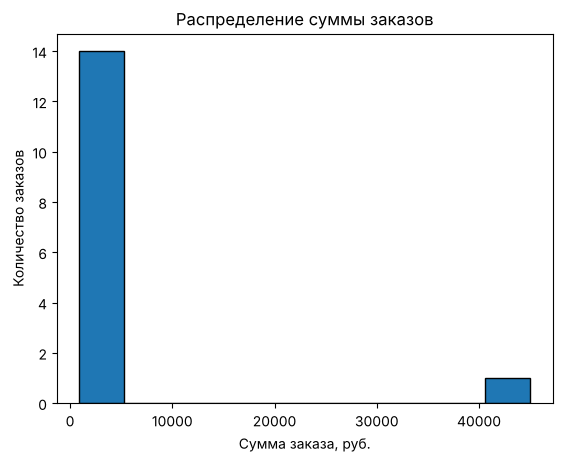

In [19]:
import matplotlib.pyplot as plt

store_df["order_sum"].plot(kind="hist", bins=10, edgecolor="black")
plt.title("Распределение суммы заказов")
plt.xlabel("Сумма заказа, руб.")
plt.ylabel("Количество заказов")
plt.show()

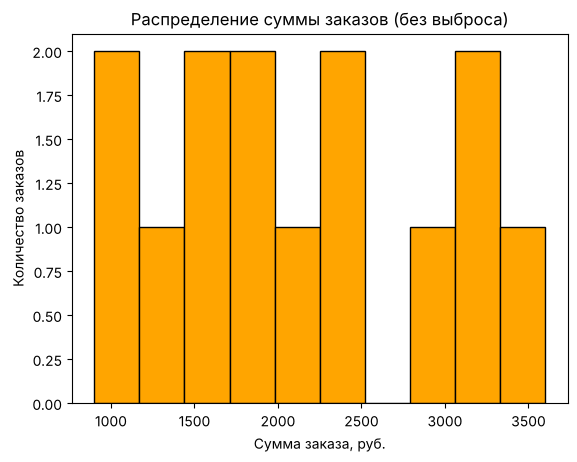

In [20]:
# для сравнения — гистограмма без заказа на 45000 руб.
store_df[store_df["order_sum"] < 45000]["order_sum"].plot(kind="hist", bins=10, edgecolor="black", color="orange")
plt.title("Распределение суммы заказов (без выброса)")
plt.xlabel("Сумма заказа, руб.")
plt.ylabel("Количество заказов")
plt.show()

**Анализ распределения и вывод:**

На первой гистограмме почти все заказы (14 из 15) попали в первый столбец (примерно 900–5300 руб.), затем идёт длинный пустой промежуток,
и в последнем столбце справа стоит один заказ на 45000 руб. Из-за этого выброса диапазон по оси X растягивается до 45000 руб.,
ширина каждого столбца становится около 4400 руб., и вся структура основной массы заказов «сжимается» в один столбец — по такой гистограмме нельзя понять, как распределены обычные заказы.

Если убрать выброс (вторая гистограмма), видно реальное распределение: суммы заказов лежат в диапазоне 900–3600 руб.,
чаще всего встречаются заказы примерно от 1000 до 2500 руб., а заказов дороже 3000 руб. немного.

**Вывод:** один заказ с существенно большей суммой сильно искажает визуальное представление данных — он растягивает шкалу и скрывает форму распределения основной массы наблюдений, а распределение выглядит сильно скошенным вправо.
Поэтому перед построением графиков стоит проверять данные на выбросы и при необходимости строить графики отдельно без них (или использовать, например, логарифмическую шкалу).